<a href="https://colab.research.google.com/github/ranispl/FSOI/blob/develop/Scat_plot.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install cartopy


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 40.6 MB/s eta 0:00:00


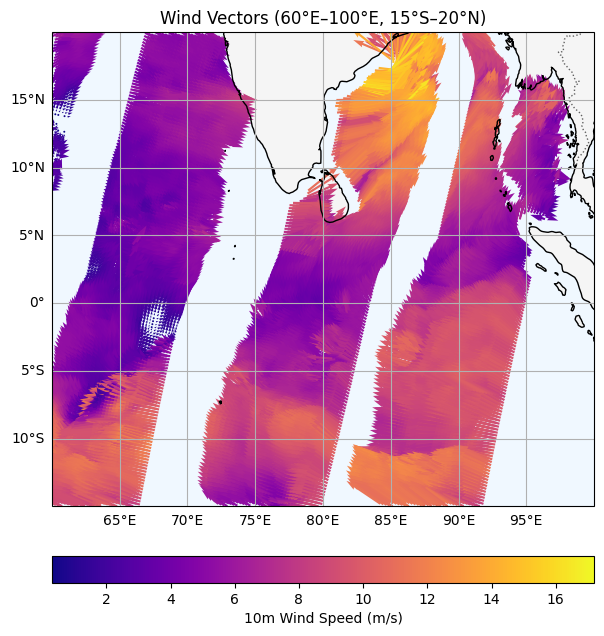

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# 1. Load your dataset
col_names = ['YR', 'MN', 'DY', 'HR', 'MI', 'SE', 'LAT', 'LON', 'WD10', 'WS10']
df = pd.read_csv('ascatw_06z.out', sep=r'\s+', header=None, names=col_names, usecols=range(10), skiprows=1)

# Convert relevant columns to numeric, coercing errors to NaN
for col in ['YR', 'MN', 'DY', 'HR', 'MI', 'SE', 'LAT', 'LON', 'WD10', 'WS10']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Drop rows with NaN values that resulted from coercion (if any)
df.dropna(inplace=True)

# 2. Filter data for 60°E to 100°E longitude and 15°S (-15) to 20°N (+20) latitude
filtered_df = df[(df['LON'] >= 60) & (df['LON'] <= 100) &
                (df['LAT'] >= -15) & (df['LAT'] <= 20)].copy()

# 3. Calculate meteorological u and v vector components
wd_rad = np.radians(filtered_df['WD10'])
filtered_df['u'] = -filtered_df['WS10'] * np.sin(wd_rad)
filtered_df['v'] = -filtered_df['WS10'] * np.cos(wd_rad)

# 4. Create the plot using Cartopy
fig = plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.PlateCarree())

# Set map extent to 60°E-100°E, 15°S-20°N
ax.set_extent([60, 100, -15, 20], crs=ccrs.PlateCarree())

# Add geographic features
ax.add_feature(cfeature.COASTLINE, linewidth=1.0)
ax.add_feature(cfeature.BORDERS, linestyle=':', alpha=0.6)
ax.add_feature(cfeature.LAND, facecolor='whitesmoke')
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')

gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
gl.top_labels = False
gl.right_labels = False

# 5. Plot wind vectors
q = ax.quiver(filtered_df['LON'].values, filtered_df['LAT'].values,
              filtered_df['u'].values, filtered_df['v'].values,
              filtered_df['WS10'].values, cmap='plasma',
              transform=ccrs.PlateCarree(), scale=150, width=0.004)

# Colorbar for Wind Speed
cbar = plt.colorbar(q, ax=ax, orientation='horizontal', pad=0.08, shrink=0.7)
cbar.set_label('10m Wind Speed (m/s)')

plt.title('Wind Vectors (60°E–100°E, 15°S–20°N)', fontsize=12)
plt.savefig('wind_vectors_60_100.png', dpi=300, bbox_inches='tight')
plt.show()